# NYC building facades: a neural network for unsafe facade inspections

**Team:** Amelia, Jerome, Kazuko, Sahil · **Course:** AI Methods I – Day 4: Neural networks (IAAC MaAI 2026/27) · **Track:** A1 (MLP on tables)

On Day 2 we trained a random forest that predicts, **before an inspection**, whether a NYC facade inspection (FISP, Local Law 11)
will come out **UNSAFE**. Today we train a **neural network (MLP)** on exactly the same data, target, features and test set,
look at what it learned, and check honestly whether it does better than the Day 2 model.

## 0. Introduction

**Use case – three questions**

1. **Who uses the model, and for what?** The NYC Department of Buildings or a facade consultant, at the start of a new cycle, to
   **rank buildings by risk** and decide which facades to inspect first.
2. **What does a mistake cost?** Missing an UNSAFE facade (false negative) can let bricks or terra cotta fall on the sidewalk.
   A false alarm (false positive) only means an earlier inspection. So **recall matters more than precision**: we use **F2**.
3. **What is good enough, compared with what?** The network is useful only if it beats the simple baselines and is **at least as good
   as our Day 2 random forest** (test F2 0.631, recall 0.920, average precision 0.605). Because the real use is a ranking, we also report
   **average precision** and the share of UNSAFE facades found in the riskiest 10% / 20% of buildings.

**Data**

| | |
|---|---|
| **Name** | DOB NOW: Safety – Facades Compliance Filings ([NYC Open Data, xubg-57si](https://data.cityofnewyork.us/d/xubg-57si)) |
| **Version used** | `facades_clean.csv`, the cleaned table from our [Day 2 cleaning notebook](https://github.com/iaac-maai/group1_day2_assignment/blob/main/notebook/data_cleaning_and_EDA.ipynb), downloaded by this notebook from our [Day 3 repository](https://github.com/iaac-maai/group1_day3_assignment) |
| **Licence** | NYC Open Data, free public use under the [NYC Terms of Use](https://www.nyc.gov/home/terms-of-use.page) |
| **Size** | 67,659 cleaned filings → 54,049 **initial** filings of 15,767 buildings used for the model |
| **One example is** | one initial facade inspection report of one building in one 5-year cycle |

### Setup

Everything runs on a laptop CPU in a few minutes. Paths are relative to this notebook (it lives in `notebook/`).

In [1]:
import copy
import json
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import torch
from torch import nn
from torchinfo import summary

print(f"torch {torch.__version__}, scikit-learn {sklearn.__version__}, pandas {pd.__version__}, numpy {np.__version__}")

torch 2.15.0+cu132, scikit-learn 1.9.1, pandas 3.0.5, numpy 2.5.3


In [2]:
DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

RANDOM_STATE = 42          # the same seed as on Day 2: same split, same test set
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
DEVICE = "cpu"             # small tabular data: a CPU is enough

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)


def save_fig(name, folder=FIG_DIR):
    # Save the current figure as a PNG
    path = folder / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

The helper functions from class notebook 01 (`parameter_table`, `layer_outputs`, `draw_network`), copied unchanged so this notebook runs on its own.

In [3]:
def parameter_table(model):
    # One row per weight matrix and bias vector: its shape, how many numbers it holds and their spread
    rows = []
    for name, p in model.named_parameters():
        values = p.detach().cpu().numpy()
        rows.append({"parameter": name, "shape": tuple(values.shape), "count": values.size,
                     "mean": values.mean(), "std": values.std(), "min": values.min(), "max": values.max()})
    return pd.DataFrame(rows).set_index("parameter")


def layer_outputs(model, x):
    # Pass x through a Sequential model one layer at a time and keep what comes out of each layer
    outputs = []
    with torch.no_grad():
        for name, layer in model.named_children():
            x = layer(x)
            outputs.append((f"{name}: {layer.__class__.__name__}", x.cpu()))
    return outputs


def draw_network(model, input_names=None, output_names=None, max_neurons=12, weight_scale=None, title=None, ax=None):
    # Draw the Linear (dense) layers of a model: circles are neurons, lines are weights.
    # Blue = positive weight, red = negative; the thicker and darker the line, the larger the weight.
    # weight_scale = the weight drawn at full strength (default: the largest one in each layer).
    # Wide layers only show their first `max_neurons` neurons.
    layers = list(model) if isinstance(model, nn.Sequential) else [model]
    linears = [layer for layer in layers if isinstance(layer, nn.Linear)]

    # A label under each layer, e.g. "Linear 8→32 + ReLU"
    labels = []
    for layer in layers:
        if isinstance(layer, nn.Linear):
            labels.append(f"Linear {layer.in_features}→{layer.out_features}")
        elif not isinstance(layer, nn.Dropout) and labels:
            labels[-1] += f"\n+ {layer.__class__.__name__}"

    sizes = [linears[0].in_features] + [layer.out_features for layer in linears]
    shown = [min(n, max_neurons) for n in sizes]
    spacing = [min(2 / max(n - 1, 1), 0.6) for n in shown]           # small layers are spread out more
    ys = [(np.arange(n) - (n - 1) / 2) * -gap for n, gap in zip(shown, spacing)]   # vertical position of each neuron

    if ax is None:
        fig, ax = plt.subplots(figsize=(2.8 * len(sizes) + 1, 6))

    # Lines: one per weight
    for l, layer in enumerate(linears):
        W = layer.weight.detach().cpu().numpy()[:shown[l + 1], :shown[l]]   # (outputs, inputs)
        scale = weight_scale or np.abs(W).max()
        for j, y_out in enumerate(ys[l + 1]):
            for i, y_in in enumerate(ys[l]):
                strength = min(abs(W[j, i]) / scale, 1)
                ax.plot([l, l + 1], [y_in, y_out], color="tab:blue" if W[j, i] > 0 else "tab:red",
                        lw=0.3 + 3 * strength, alpha=0.15 + 0.75 * strength, zorder=1)
                if W.size <= 12:                                           # tiny network: write the value too
                    ax.text(l + 0.3, y_in + 0.3 * (y_out - y_in), f"{W[j, i]:+.2f}", fontsize=9,
                            ha="center", va="bottom", color="dimgrey")

    # Circles: one per neuron, and the labels
    circle_size = np.clip(2500 / max(shown), 60, 700)
    for l, (n, y) in enumerate(zip(sizes, ys)):
        ax.scatter(np.full(len(y), l), y, s=circle_size, color="lightgrey" if l == 0 else "white",
                   edgecolors="black", zorder=2)
        if n > len(y):
            ax.text(l, y.min() - 0.12, f"+ {n - len(y)} more", ha="center", va="top", fontsize=9)
        ax.text(l, -1.3, "Input" if l == 0 else labels[l - 1], ha="center", va="top", fontsize=10)
    for name, y in zip(input_names or [], ys[0]):
        ax.text(-0.15, y, name, ha="right", va="center", fontsize=9)
    for name, y in zip(output_names or [], ys[-1]):
        ax.text(len(sizes) - 0.85, y, name, ha="left", va="center", fontsize=9)

    n_params = sum(p.numel() for p in model.parameters())
    ax.set_title(title or f"{n_params:,} parameters")
    ax.set_xlim(-1, len(sizes) - 0.2)
    ax.set_ylim(-1.7, 1.2)
    ax.axis("off")
    return ax

## 1. Data and splits

### 1.1 Load the cleaned filings

The data is **not committed** to GitHub. If `data/facades_clean.csv` is missing, it is downloaded from our Day 3 repository
(the same file our Day 2 cleaning notebook produces).

In [4]:
CLEAN_URL = "https://raw.githubusercontent.com/iaac-maai/group1_day3_assignment/main/data/facades_clean.csv"
clean_path = DATA_DIR / "facades_clean.csv"

if not clean_path.exists():
    print("Downloading the cleaned filings (about 15 MB)...")
    urllib.request.urlretrieve(CLEAN_URL, clean_path)

df = pd.read_csv(clean_path, low_memory=False)
print(f"Facade filings: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(3)

Facade filings: 67,659 rows x 42 columns


,TR6_NO,BIN,BOROUGH,BLOCK,LOT,HOUSE_NO,STREET_NAME,FILING_TYPE,CYCLE,SEQUENCE_NO,FILING_YEAR,FILING_STATUS,IS_UNSAFE,PRIOR_STATUS,HAS_PRIOR_CYCLE,EXTERIOR_WALL_TYPES,EXTERIOR_WALL_MATERIALS,WALL_TYPE_BRICK_MASONRY,WALL_TYPE_OTHER,WALL_TYPE_MASONRY_LOAD_BEARING_WALL,WALL_TYPE_TERRA_COTTA,WALL_TYPE_MASONRY_CAVITY_WALL,WALL_TYPE_STEEL_FRAME,WALL_TYPE_CONCRETE,WALL_TYPE_CONCRETE_FRAME,MATERIAL_MASONRY,MATERIAL_OTHER,MATERIAL_TERRA_COTTA,MATERIAL_NATURAL_STONE,MATERIAL_CONCRETE,MATERIAL_STUCCO_EIFS,MATERIAL_GLASS,MATERIAL_METAL,FIELD_INSPECTION_COMPLETED_DATE,FILING_DATE,PRIOR_CYCLE_FILING_DATE,QEWI_SIGNED_DATE,DAYS_INSPECTION_TO_FILING,LATE_FILING_AMT,FAILURE_TO_FILE_AMT,FAILURE_TO_CORRECT_AMT,TOTAL_PENALTY_AMT
0,TR6-611824-NA-I1,"4,436,310.000",QUEENS,"16,114.000",2,8201,HAMMELS BOULEVARD,INITIAL,6.000,4.000,"2,009.000",SAFE,0,SAFE,1,OTHER,OTHER,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,2008-03-11,2009-10-16,2003-03-25,2009-09-30,584.000,0.000,0.000,0.000,0.000
1,TR6-611612-NA-A1,"4,208,850.000",QUEENS,"9,757.000",23,90-04,161 STREET,AMENDED,6.000,1.000,"2,010.000",SWARMP,0,NaN,0,OTHER,OTHER,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,NaN,2010-12-15,NaN,NaN,NaN,"44,000.000","15,000.000","707,500.000","766,500.000"
2,TR6-802744-8A-I1,"1,019,150.000",MANHATTAN,894.000,52,148,EAST 39 STREET,INITIAL,8.000,1.000,"2,018.000",SWARMP,0,SWARMP,1,BRICK MASONRY,MASONRY,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,2018-03-22,2018-04-09,2012-02-21,2018-09-27,18.000,"3,500.000","1,000.000",0.000,"4,500.000"


### 1.2 Same rows, target and features as Day 2

- Only **initial** filings (amended and subsequent filings only exist after repairs or after an UNSAFE result: leakage).
- Target `IS_UNSAFE`: 1 = UNSAFE, 0 = SAFE or SWARMP.
- 19 features known **before** the inspection: the previous cycle's result, borough, cycle, 8 facade materials and 8 wall types.

In [5]:
df_model = df[df["FILING_TYPE"] == "INITIAL"].copy()
df_model = df_model[df_model["BIN"].notna() & df_model["CYCLE"].notna()].reset_index(drop=True)

material_features = [c for c in df_model.columns if c.startswith("MATERIAL_")]
wall_features = [c for c in df_model.columns if c.startswith("WALL_TYPE_")]
nominal_features = ["PRIOR_STATUS", "BOROUGH", "CYCLE"]
binary_features = material_features + wall_features
features = nominal_features + binary_features

df_model["PRIOR_STATUS"] = df_model["PRIOR_STATUS"].fillna("NO PRIOR CYCLE")
df_model["CYCLE"] = df_model["CYCLE"].astype(int).astype(str)

X = df_model[features].copy()
X[binary_features] = X[binary_features].astype(float)
y = df_model["IS_UNSAFE"].astype(int)
groups = df_model["BIN"]

print(f"{len(X):,} initial filings of {groups.nunique():,} buildings, {X.shape[1]} features")
print(f"UNSAFE: {y.sum():,} filings ({y.mean():.1%})")
X.head()

54,049 initial filings of 15,767 buildings, 19 features
UNSAFE: 12,552 filings (23.2%)


,PRIOR_STATUS,BOROUGH,CYCLE,MATERIAL_MASONRY,MATERIAL_OTHER,MATERIAL_TERRA_COTTA,MATERIAL_NATURAL_STONE,MATERIAL_CONCRETE,MATERIAL_STUCCO_EIFS,MATERIAL_GLASS,MATERIAL_METAL,WALL_TYPE_BRICK_MASONRY,WALL_TYPE_OTHER,WALL_TYPE_MASONRY_LOAD_BEARING_WALL,WALL_TYPE_TERRA_COTTA,WALL_TYPE_MASONRY_CAVITY_WALL,WALL_TYPE_STEEL_FRAME,WALL_TYPE_CONCRETE,WALL_TYPE_CONCRETE_FRAME
0,SAFE,QUEENS,6,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000
1,SWARMP,MANHATTAN,8,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,SAFE,BROOKLYN,7,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000
3,NO PRIOR CYCLE,MANHATTAN,9,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000
4,UNSAFE,BRONX,6,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


### 1.3 Split before anything else: the Day 2 test set, then a validation set

- **Test set:** exactly the Day 2 split (`StratifiedGroupKFold`, 5 parts, `random_state=42`, first part = 20%). All filings of a
  building stay on one side, and the share of UNSAFE is the same on both sides. It stays locked until section 6.
- **Validation set:** a network needs a set it does not train on to draw the curves, stop training and choose the threshold.
  We take the first of the Day 2 cross-validation folds of the training set (again grouped by building).

In [6]:
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(splitter.split(X, y, groups))
X_trainval, X_test = X.iloc[trainval_idx], X.iloc[test_idx]
y_trainval, y_test = y.iloc[trainval_idx], y.iloc[test_idx]
groups_trainval = groups.iloc[trainval_idx]

inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fit_idx, val_idx = next(inner.split(X_trainval, y_trainval, groups_trainval))
X_train, X_val = X_trainval.iloc[fit_idx], X_trainval.iloc[val_idx]
y_train, y_val = y_trainval.iloc[fit_idx], y_trainval.iloc[val_idx]

split_table = pd.DataFrame({
    "filings": [len(X_train), len(X_val), len(X_test)],
    "buildings": [groups_trainval.iloc[fit_idx].nunique(), groups_trainval.iloc[val_idx].nunique(),
                  groups.iloc[test_idx].nunique()],
    "% UNSAFE": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["train", "validation", "test (Day 2 test set)"])
print("Buildings shared between train and test:", len(set(groups_trainval) & set(groups.iloc[test_idx])))
print("Buildings shared between train and validation:",
      len(set(groups_trainval.iloc[fit_idx]) & set(groups_trainval.iloc[val_idx])))
split_table.round(1)

Buildings shared between train and test: 0
Buildings shared between train and validation: 0


,filings,buildings,% UNSAFE
train,34593,10052,23.200
validation,8646,2534,23.200
test (Day 2 test set),10810,3181,23.200


### 1.4 Preprocessing and scaling (fitted on the training set only)

A network needs numbers on a similar scale. The same preprocessing as Day 2 (most-frequent imputation, one-hot encoding of the three
nominal features), followed by a `StandardScaler`. Everything is **fitted on the training set only** and saved later as `scaler.joblib`.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocess = Pipeline([
    ("columns", ColumnTransformer([
        ("nom", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), nominal_features),
        ("bin", SimpleImputer(strategy="most_frequent"), binary_features),
    ])),
    ("scaler", StandardScaler()),
])
preprocess.fit(X_train)
input_names = [n.split("__", 1)[1] for n in preprocess.named_steps["columns"].get_feature_names_out()]
N_INPUTS = len(input_names)


def to_tensors(X_part, y_part):
    return (torch.tensor(preprocess.transform(X_part), dtype=torch.float32),
            torch.tensor(y_part.to_numpy(), dtype=torch.float32).unsqueeze(1))


X_train_t, y_train_t = to_tensors(X_train, y_train)
X_val_t, y_val_t = to_tensors(X_val, y_val)
X_test_t, y_test_t = to_tensors(X_test, y_test)
print(f"{len(features)} original columns -> {N_INPUTS} network inputs")
print(f"train {tuple(X_train_t.shape)}, validation {tuple(X_val_t.shape)}, test {tuple(X_test_t.shape)}")
pd.DataFrame(X_train_t[:3].numpy(), columns=input_names).iloc[:, :12]

19 original columns -> 31 network inputs
train (34593, 31), validation (8646, 31), test (10810, 31)


,PRIOR_STATUS_NO PRIOR CYCLE,PRIOR_STATUS_NO REPORT FILED,PRIOR_STATUS_SAFE,PRIOR_STATUS_SWARMP,PRIOR_STATUS_UNSAFE,BOROUGH_BRONX,BOROUGH_BROOKLYN,BOROUGH_MANHATTAN,BOROUGH_QUEENS,BOROUGH_STATEN ISLAND,CYCLE_10,CYCLE_6
0,-0.317,-0.199,1.168,-0.808,-0.236,-0.382,-0.399,-1.222,2.604,-0.091,-0.238,1.838
1,-0.317,-0.199,-0.856,1.238,-0.236,-0.382,-0.399,0.819,-0.384,-0.091,-0.238,-0.544
2,-0.317,-0.199,1.168,-0.808,-0.236,-0.382,2.509,-1.222,-0.384,-0.091,-0.238,-0.544


## 2. Baseline: the Day 2 model

Our Day 2 final model, rebuilt with the same settings (random forest, 200 trees, `max_depth=12`, `max_features=0.5`,
`min_samples_leaf=1`, `class_weight="balanced"`, decision threshold **0.30**) and trained on the same training set (train + validation),
plus the simple baselines. Here we only check it on the validation set; the test comparison is in section 6.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (fbeta_score, recall_score, precision_score, balanced_accuracy_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay)

RF_THRESHOLD = 0.30
day2_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("nom", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), nominal_features),
        ("bin", SimpleImputer(strategy="most_frequent"), binary_features),
    ])),
    ("model", RandomForestClassifier(n_estimators=200, max_depth=12, max_features=0.5, min_samples_leaf=1,
                                     class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
])


def scores(y_true, proba, threshold):
    # All the metrics we report, for probabilities and a decision threshold
    pred = (proba >= threshold).astype(int)
    return {"F2": fbeta_score(y_true, pred, beta=2, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "precision": precision_score(y_true, pred, zero_division=0),
            "balanced accuracy": balanced_accuracy_score(y_true, pred),
            "average precision": average_precision_score(y_true, proba)}


# For the validation check, the random forest is fitted on the training part only (like the network)
rf_check = copy.deepcopy(day2_model).fit(X_train, y_train)
rf_val_proba = rf_check.predict_proba(X_val)[:, 1]
rng = np.random.default_rng(RANDOM_STATE)

baseline_val = pd.DataFrame({
    "Always 'not UNSAFE'": scores(y_val, np.zeros(len(y_val)), 0.5),
    "Always UNSAFE ('inspect everything')": scores(y_val, np.ones(len(y_val)), 0.5),
    "Random": scores(y_val, rng.random(len(y_val)), 1 - y_train.mean()),
    "Day 2 random forest (thr. 0.30)": scores(y_val, rf_val_proba, RF_THRESHOLD),
}).T
baseline_val

,F2,recall,precision,balanced accuracy,average precision
Always 'not UNSAFE',0.000,0.000,0.000,0.500,0.232
Always UNSAFE ('inspect everything'),0.602,1.000,0.232,0.500,0.232
Random,0.233,0.233,0.237,0.503,0.236
Day 2 random forest (thr. 0.30),0.628,0.893,0.286,0.610,0.603


> ✏️ **Team reading (write in your own words):** which baseline is hardest to beat on F2, and why is 'inspect everything' so strong with this metric?

## 3. Model and training

### 3.1 The architecture

A small MLP built with `nn.Sequential`: the inputs → 32 neurons → 16 neurons → **1 output** (a score, turned into the probability of UNSAFE
with a sigmoid). ReLU activations, and dropout to limit overfitting. The function `make_mlp` is the **exact code** a user needs to rebuild
the network before loading the weights (it is copied into the model card).

In [9]:
def make_mlp(n_inputs=N_INPUTS, hidden=(32, 16), dropout=0.2):
    # Inputs -> hidden layers (Linear + ReLU + Dropout) -> one output score (logit of UNSAFE)
    layers, size = [], n_inputs
    for width in hidden:
        layers += [nn.Linear(size, width), nn.ReLU(), nn.Dropout(dropout)]
        size = width
    layers.append(nn.Linear(size, 1))
    return nn.Sequential(*layers)


torch.manual_seed(RANDOM_STATE)
mlp_untrained = make_mlp()
summary(mlp_untrained, input_size=(1, N_INPUTS), col_names=["input_size", "output_size", "num_params"])

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                               [1, 31]                   [1, 1]                    --
├─Linear: 1-1                            [1, 31]                   [1, 32]                   1,024
├─ReLU: 1-2                              [1, 32]                   [1, 32]                   --
├─Dropout: 1-3                           [1, 32]                   [1, 32]                   --
├─Linear: 1-4                            [1, 32]                   [1, 16]                   528
├─ReLU: 1-5                              [1, 16]                   [1, 16]                   --
├─Dropout: 1-6                           [1, 16]                   [1, 16]                   --
├─Linear: 1-7                            [1, 16]                   [1, 1]                    17
Total params: 1,569
Trainable params: 1,569
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.

### 3.2 Training loop

- **Loss:** `BCEWithLogitsLoss` with `pos_weight` = (#not UNSAFE / #UNSAFE), the network version of `class_weight="balanced"`:
  a missed UNSAFE facade weighs about 3× more.
- **Optimizer:** Adam, learning rate 0.001, mini-batches of 256 filings.
- **Stopping:** up to 60 epochs; we keep the weights of the epoch with the **lowest validation loss** and stop after 10 epochs without improvement (early stopping).

In [10]:
POS_WEIGHT = torch.tensor([(y_train == 0).sum() / (y_train == 1).sum()], dtype=torch.float32)
print(f"pos_weight = {POS_WEIGHT.item():.2f}")


def predict_proba(model, X_t):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(X_t)).squeeze(1).numpy()


def train_mlp(hidden=(32, 16), dropout=0.2, lr=1e-3, batch_size=256, max_epochs=60, patience=10, seed=RANDOM_STATE):
    torch.manual_seed(seed)
    model = make_mlp(hidden=hidden, dropout=dropout)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_train_t, y_train_t), batch_size=batch_size,
                                         shuffle=True, generator=torch.Generator().manual_seed(seed))
    history, best_loss, best_state, best_epoch = [], np.inf, None, 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        batch_losses = []
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val_t), y_val_t).item()
        val_proba = predict_proba(model, X_val_t)
        history.append({"epoch": epoch, "train loss": np.mean(batch_losses), "validation loss": val_loss,
                        "validation AP": average_precision_score(y_val, val_proba)})
        if val_loss < best_loss - 1e-4:
            best_loss, best_state, best_epoch = val_loss, copy.deepcopy(model.state_dict()), epoch
        elif epoch - best_epoch >= patience:
            break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history).set_index("epoch"), best_epoch


start = time.time()
mlp, history, best_epoch = train_mlp()
print(f"Trained in {time.time() - start:.0f} s, {len(history)} epochs, best epoch: {best_epoch}")
history.tail()

pos_weight = 3.31


Trained in 21 s, 57 epochs, best epoch: 47


,train loss,validation loss,validation AP
epoch,,,
53,0.867,0.865,0.594
54,0.864,0.865,0.594
55,0.863,0.866,0.594
56,0.866,0.866,0.594
57,0.862,0.866,0.594


Figure saved to ../figures/01_training_curves.png


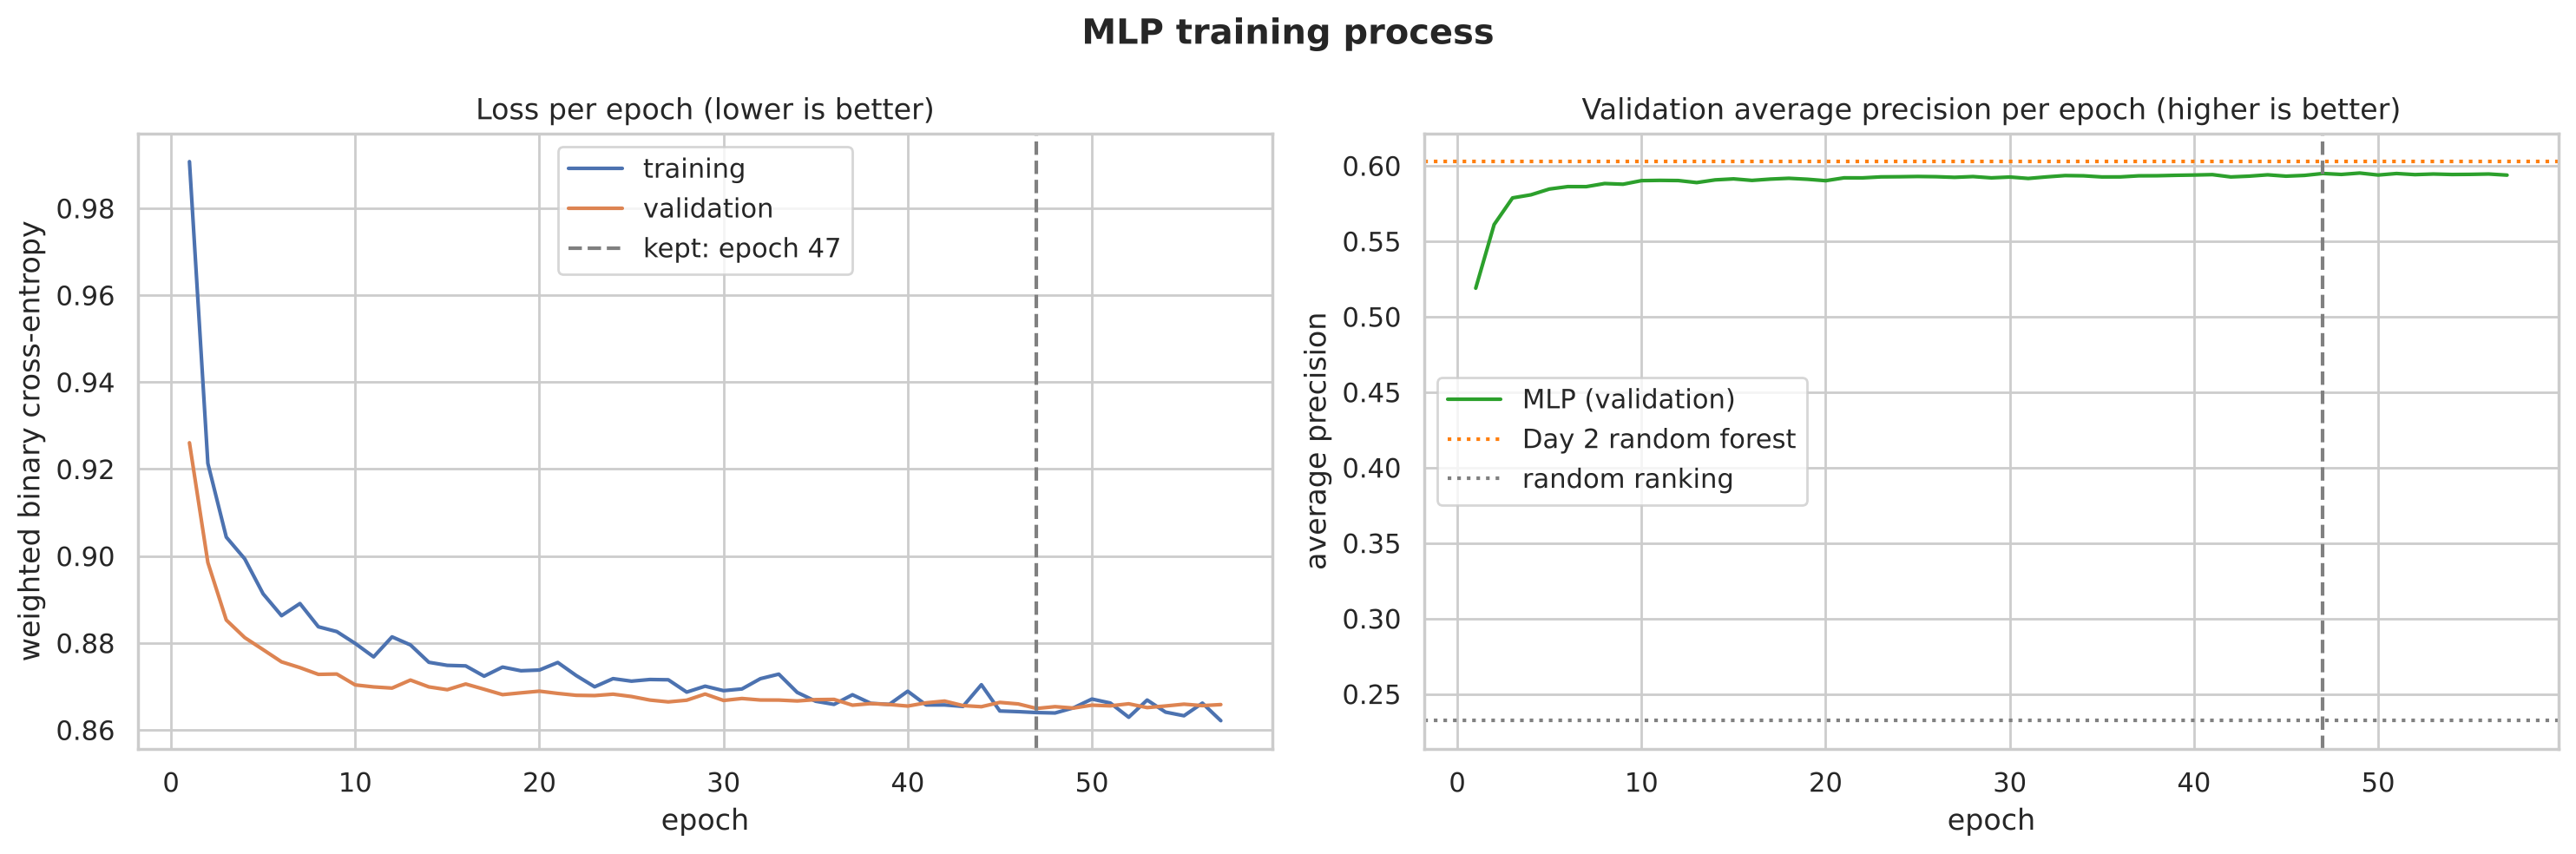

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(history.index, history["train loss"], label="training")
axes[0].plot(history.index, history["validation loss"], label="validation")
axes[0].axvline(best_epoch, color="grey", ls="--", label=f"kept: epoch {best_epoch}")
axes[0].set(title="Loss per epoch (lower is better)", xlabel="epoch", ylabel="weighted binary cross-entropy")
axes[0].legend()
axes[1].plot(history.index, history["validation AP"], color="tab:green", label="MLP (validation)")
axes[1].axhline(average_precision_score(y_val, rf_val_proba), color="tab:orange", ls=":", label="Day 2 random forest")
axes[1].axhline(y_val.mean(), color="grey", ls=":", label="random ranking")
axes[1].axvline(best_epoch, color="grey", ls="--")
axes[1].set(title="Validation average precision per epoch (higher is better)", xlabel="epoch", ylabel="average precision")
axes[1].legend()
plt.suptitle("MLP training process", fontweight="bold")
plt.tight_layout()
save_fig("01_training_curves")
plt.show()

> ✏️ **Team reading (write in your own words):** is the network still learning at the end? Where do the training and validation curves separate (overfitting)? Why did early stopping keep this epoch? Note that the training loss includes dropout, so it can sit above the validation loss.

## 4. Diagnosis: what did the network learn?

### 4.1 Parameters and weights, before and after training

In [12]:
parameter_table(mlp)

,shape,count,mean,std,min,max
parameter,,,,,,
0.weight,"(32, 31)",992,-0.010,0.146,-0.559,0.435
0.bias,"(32,)",32,-0.266,0.187,-0.712,0.206
3.weight,"(16, 32)",512,-0.022,0.207,-0.667,0.466
3.bias,"(16,)",16,0.071,0.069,-0.046,0.156
6.weight,"(1, 16)",16,0.119,0.343,-0.317,0.667
6.bias,"(1,)",1,-0.136,0.000,-0.136,-0.136


Figure saved to ../figures/02_network_before_after.png


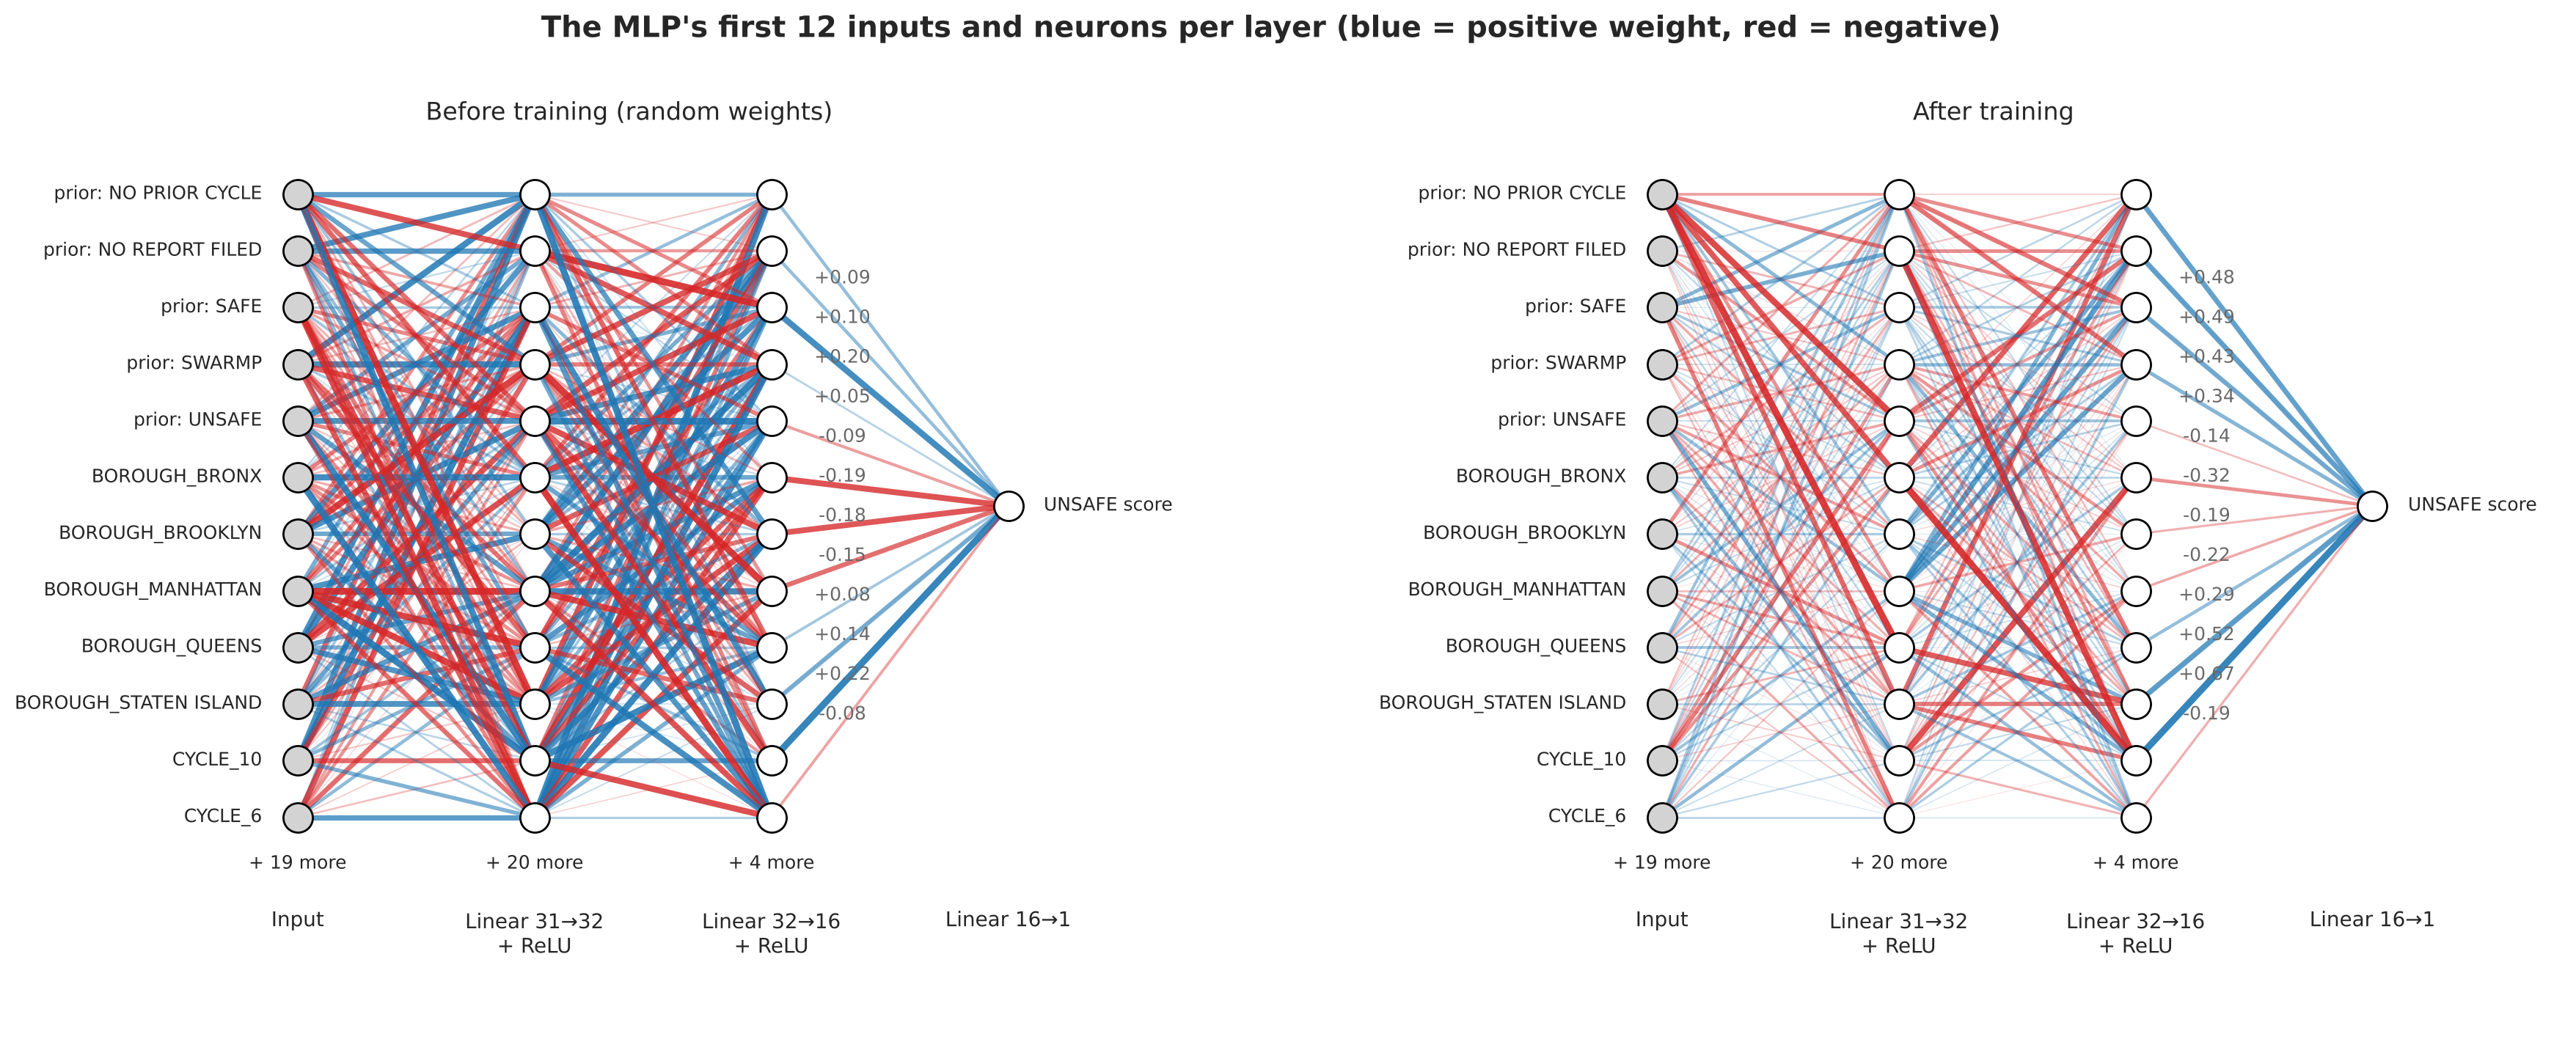

In [13]:
short_names = [n.replace("MATERIAL_", "mat: ").replace("WALL_TYPE_", "wall: ").replace("PRIOR_STATUS_", "prior: ")
               for n in input_names]
fig, axes = plt.subplots(1, 2, figsize=(22, 8))
draw_network(mlp_untrained, input_names=short_names, output_names=["UNSAFE score"], ax=axes[0],
             title="Before training (random weights)")
draw_network(mlp, input_names=short_names, output_names=["UNSAFE score"], ax=axes[1],
             title="After training")
plt.suptitle("The MLP's first 12 inputs and neurons per layer (blue = positive weight, red = negative)", fontweight="bold")
save_fig("02_network_before_after")
plt.show()

> ✏️ **Team reading (write in your own words):** what changed between the two drawings? Which inputs ended up with the strongest weights?

### 4.2 Layer outputs: how the network separates buildings

We pass validation filings through the network layer by layer (`layer_outputs`) and average the 16 neurons of the last hidden layer
per **previous inspection result**, the strongest feature on Day 2.

0: Linear      -> (8646, 32)
1: ReLU        -> (8646, 32)
2: Dropout     -> (8646, 32)
3: Linear      -> (8646, 16)
4: ReLU        -> (8646, 16)
5: Dropout     -> (8646, 16)
6: Linear      -> (8646, 1)


Figure saved to ../figures/03_layer_outputs_by_prior_status.png


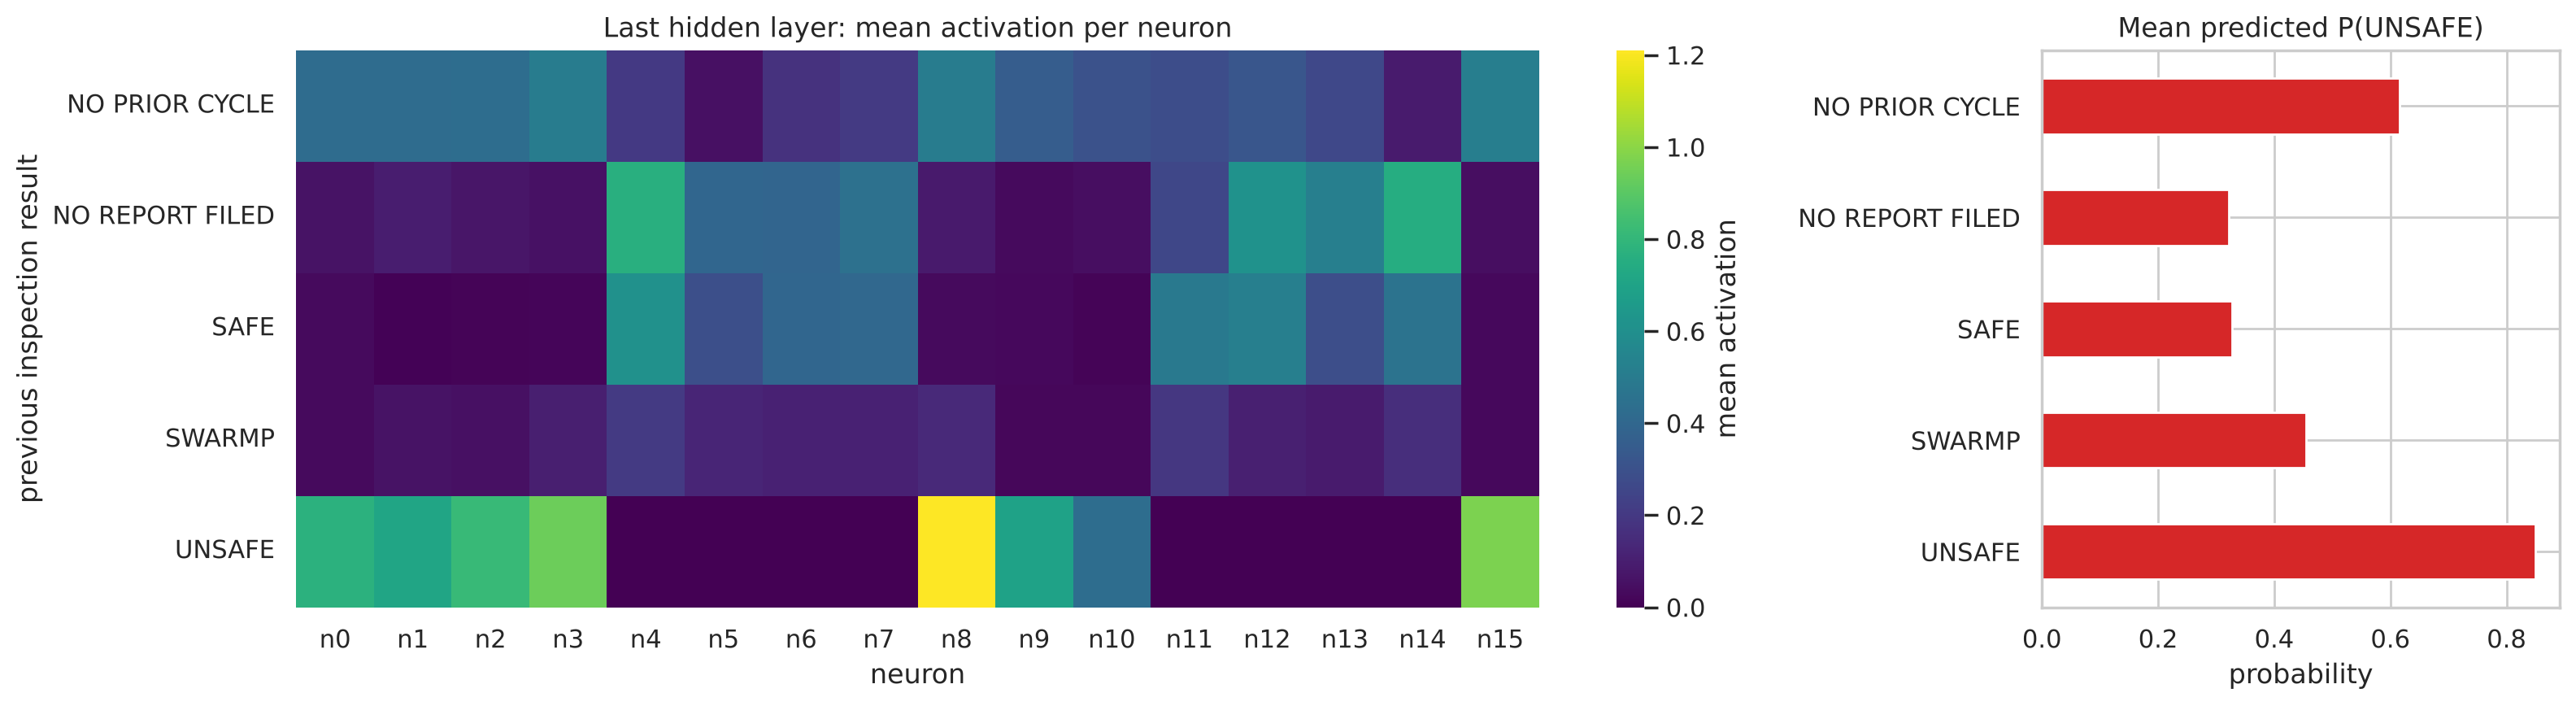

In [14]:
outputs = layer_outputs(mlp, X_val_t)
for name, out in outputs:
    print(f"{name:<14} -> {tuple(out.shape)}")

last_hidden = [out for name, out in outputs if "ReLU" in name][-1].numpy()
activation_by_prior = (pd.DataFrame(last_hidden, columns=[f"n{i}" for i in range(last_hidden.shape[1])])
                       .assign(prior=X_val["PRIOR_STATUS"].to_numpy()).groupby("prior").mean())
val_proba = predict_proba(mlp, X_val_t)
prob_by_prior = pd.Series(val_proba, index=X_val.index).groupby(X_val["PRIOR_STATUS"]).mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [3, 1]})
sns.heatmap(activation_by_prior, cmap="viridis", ax=axes[0], cbar_kws={"label": "mean activation"})
axes[0].set(title="Last hidden layer: mean activation per neuron", xlabel="neuron", ylabel="previous inspection result")
prob_by_prior.loc[activation_by_prior.index].plot.barh(ax=axes[1], color="tab:red")
axes[1].set(title="Mean predicted P(UNSAFE)", xlabel="probability", ylabel="")
axes[1].invert_yaxis()
plt.tight_layout()
save_fig("03_layer_outputs_by_prior_status")
plt.show()

> ✏️ **Team reading (write in your own words):** do some neurons 'switch on' only for previously UNSAFE facades? Does the network, like the random forest, mostly repeat history?

### 4.3 Decision threshold (chosen on validation)

The network outputs a probability; we choose the threshold that maximises F2 **on the validation set**, as we did on Day 2.

Figure saved to ../figures/04_threshold_validation.png


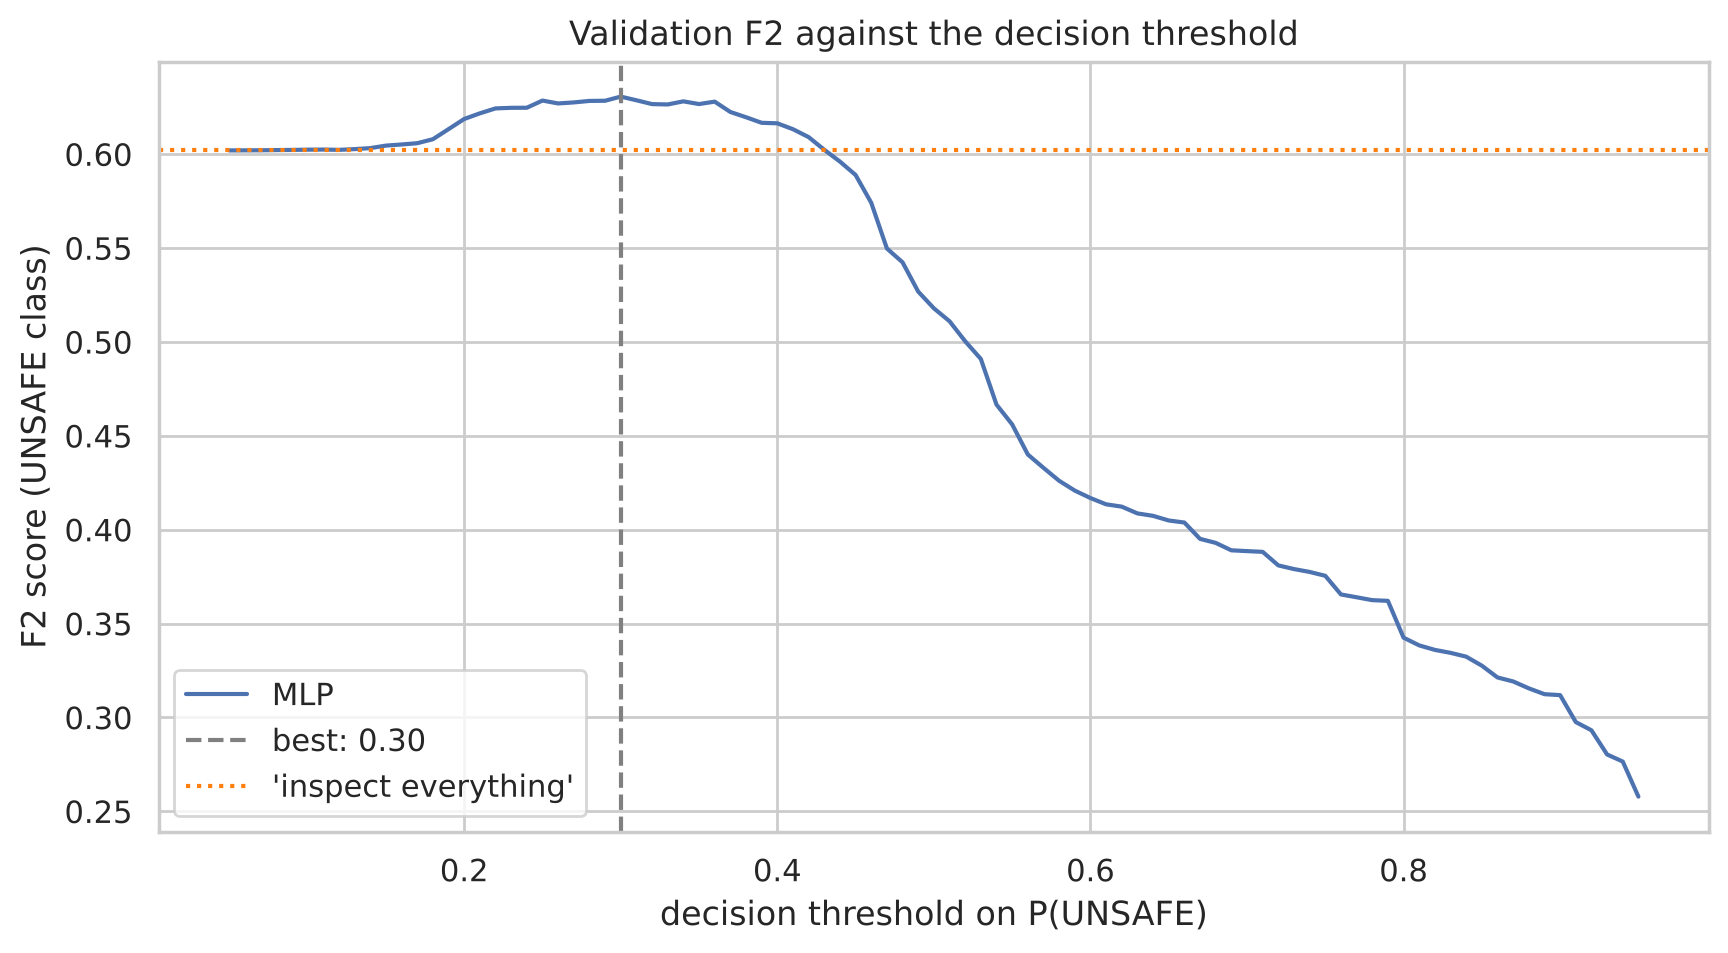

Chosen threshold: 0.30


,F2,recall,precision,balanced accuracy,average precision
MLP (validation),0.631,0.931,0.275,0.595,0.595
Day 2 random forest (validation),0.628,0.893,0.286,0.610,0.603


In [15]:
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
f2_curve = [fbeta_score(y_val, (val_proba >= t).astype(int), beta=2) for t in thresholds]
MLP_THRESHOLD = float(thresholds[int(np.argmax(f2_curve))])

plt.plot(thresholds, f2_curve, label="MLP")
plt.axvline(MLP_THRESHOLD, color="grey", ls="--", label=f"best: {MLP_THRESHOLD:.2f}")
plt.axhline(scores(y_val, np.ones(len(y_val)), 0.5)["F2"], color="tab:orange", ls=":", label="'inspect everything'")
plt.title("Validation F2 against the decision threshold")
plt.xlabel("decision threshold on P(UNSAFE)")
plt.ylabel("F2 score (UNSAFE class)")
plt.legend()
save_fig("04_threshold_validation")
plt.show()

print(f"Chosen threshold: {MLP_THRESHOLD:.2f}")
pd.DataFrame({"MLP (validation)": scores(y_val, val_proba, MLP_THRESHOLD),
              "Day 2 random forest (validation)": scores(y_val, rf_val_proba, RF_THRESHOLD)}).T

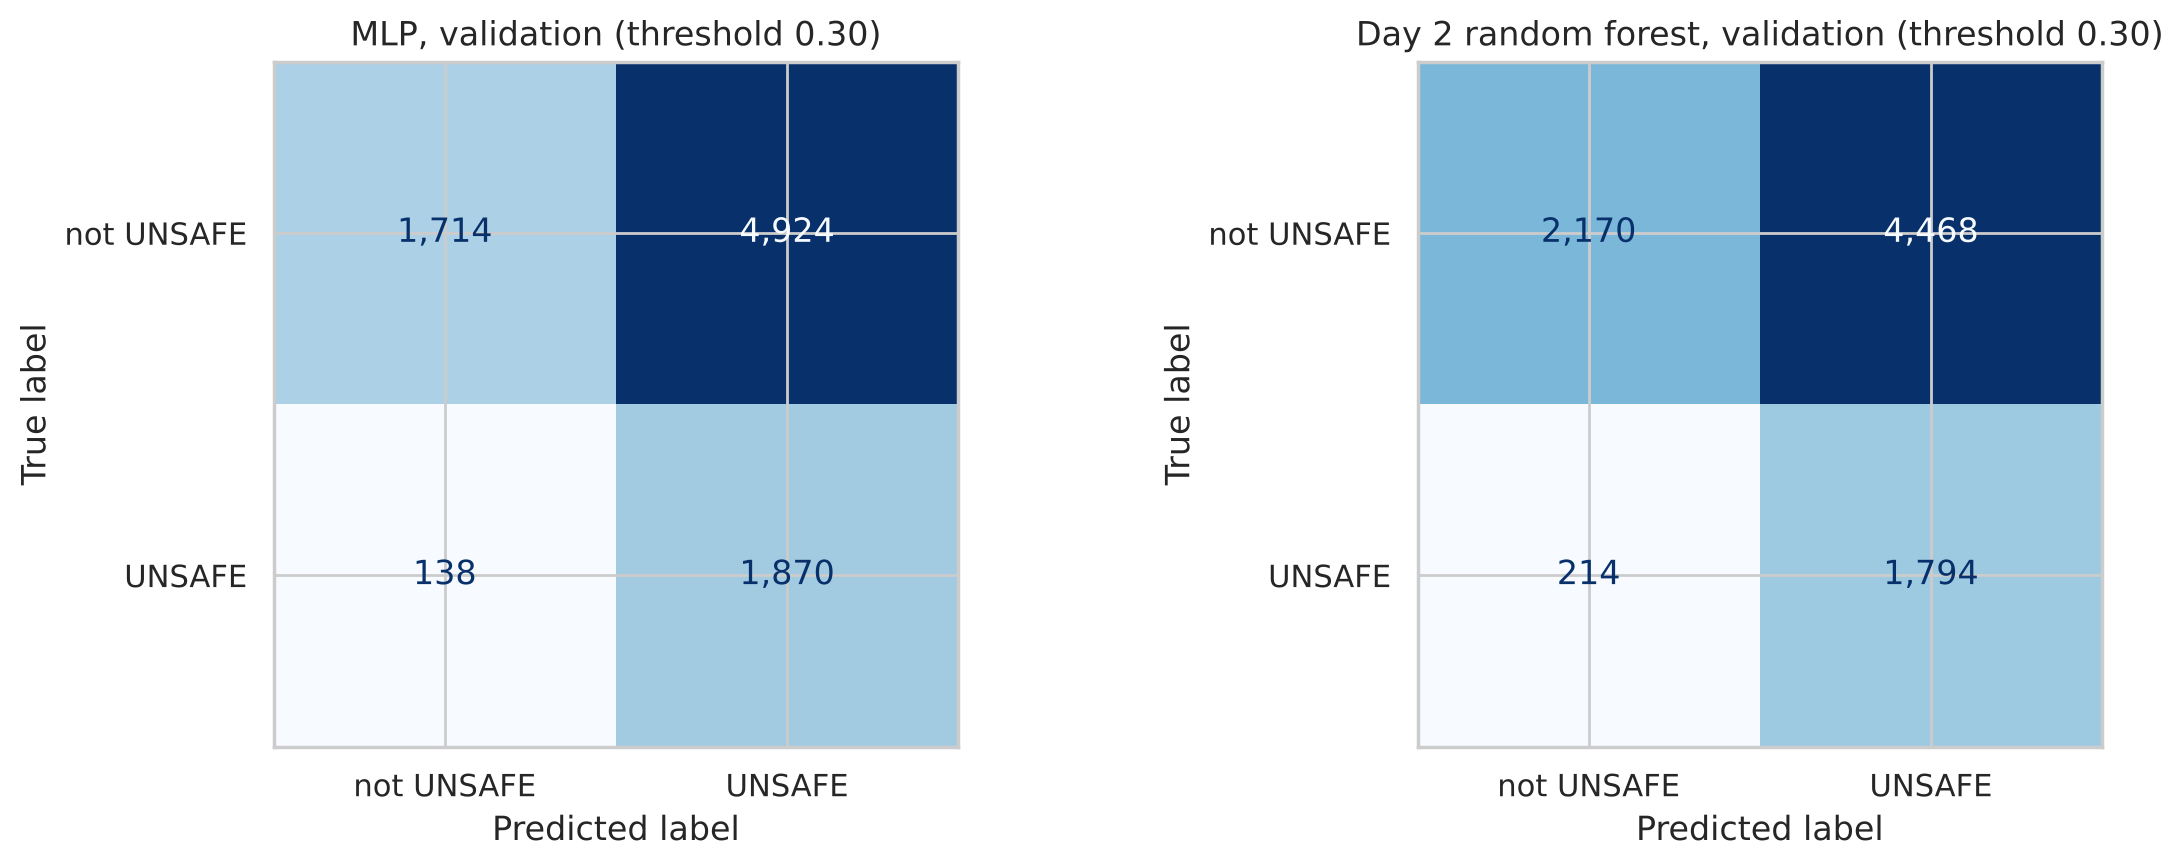

,filings,% UNSAFE,recall,precision
prior,,,,
NO PRIOR CYCLE,809,44.990,0.980,0.520
NO REPORT FILED,335,16.120,0.670,0.280
SAFE,3620,13.840,0.790,0.180
SWARMP,3409,22.090,0.990,0.230
UNSAFE,473,71.040,1.000,0.710


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, proba, thr) in zip(axes, [("MLP", val_proba, MLP_THRESHOLD), ("Day 2 random forest", rf_val_proba, RF_THRESHOLD)]):
    ConfusionMatrixDisplay(confusion_matrix(y_val, (proba >= thr).astype(int)),
                           display_labels=["not UNSAFE", "UNSAFE"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set_title(f"{name}, validation (threshold {thr:.2f})")
plt.tight_layout()
plt.show()

# Where does the MLP fail? Recall and precision per previous inspection result
val_pred = (val_proba >= MLP_THRESHOLD).astype(int)
errors = pd.DataFrame({"prior": X_val["PRIOR_STATUS"].to_numpy(), "y": y_val.to_numpy(), "pred": val_pred})
pd.DataFrame({
    "filings": errors.groupby("prior").size(),
    "% UNSAFE": errors.groupby("prior")["y"].mean() * 100,
    "recall": errors.groupby("prior").apply(lambda g: recall_score(g["y"], g["pred"], zero_division=0)),
    "precision": errors.groupby("prior").apply(lambda g: precision_score(g["y"], g["pred"], zero_division=0)),
}).round(2)

> ✏️ **Team reading (write in your own words):** for which group of buildings does the network miss the most UNSAFE facades? Is that the group inspections matter most for?

## 5. Tuning: one change at a time

Starting from the first network (32 → 16 neurons, dropout 0.2), we change **one thing per experiment** and compare on the
**validation set** only. Model selection uses validation average precision (the ranking quality, our real use case).

In [17]:
experiments = {
    "A. base: (32, 16), dropout 0.2": dict(hidden=(32, 16), dropout=0.2),
    "B. wider: (128, 64), dropout 0.2": dict(hidden=(128, 64), dropout=0.2),
    "C. no dropout: (32, 16), dropout 0.0": dict(hidden=(32, 16), dropout=0.0),
    "D. smaller: (8,), dropout 0.2": dict(hidden=(8,), dropout=0.2),
}
runs, rows = {}, []
for name, settings in experiments.items():
    start = time.time()
    model, hist, best = (mlp, history, best_epoch) if name.startswith("A.") else train_mlp(**settings)
    proba = predict_proba(model, X_val_t)
    f2s = [fbeta_score(y_val, (proba >= t).astype(int), beta=2) for t in thresholds]
    runs[name] = (model, hist, best, settings)
    rows.append({"experiment": name, "parameters": sum(p.numel() for p in model.parameters()), "best epoch": best,
                 "validation loss": hist.loc[best, "validation loss"], "validation AP": average_precision_score(y_val, proba),
                 "best F2": max(f2s), "at threshold": thresholds[int(np.argmax(f2s))]})
    print(f"{name:<40} {time.time() - start:5.1f} s")

tuning_table = pd.DataFrame(rows).set_index("experiment")
tuning_table

A. base: (32, 16), dropout 0.2             0.2 s


B. wider: (128, 64), dropout 0.2          13.9 s


C. no dropout: (32, 16), dropout 0.0      11.8 s


D. smaller: (8,), dropout 0.2             13.6 s


,parameters,best epoch,validation loss,validation AP,best F2,at threshold
experiment,,,,,,
"A. base: (32, 16), dropout 0.2",1569,47,0.865,0.595,0.631,0.300
"B. wider: (128, 64), dropout 0.2",12417,25,0.862,0.601,0.632,0.300
"C. no dropout: (32, 16), dropout 0.0",1569,37,0.864,0.598,0.633,0.250
"D. smaller: (8,), dropout 0.2",265,60,0.876,0.581,0.624,0.240


Figure saved to ../figures/05_tuning_experiments.png


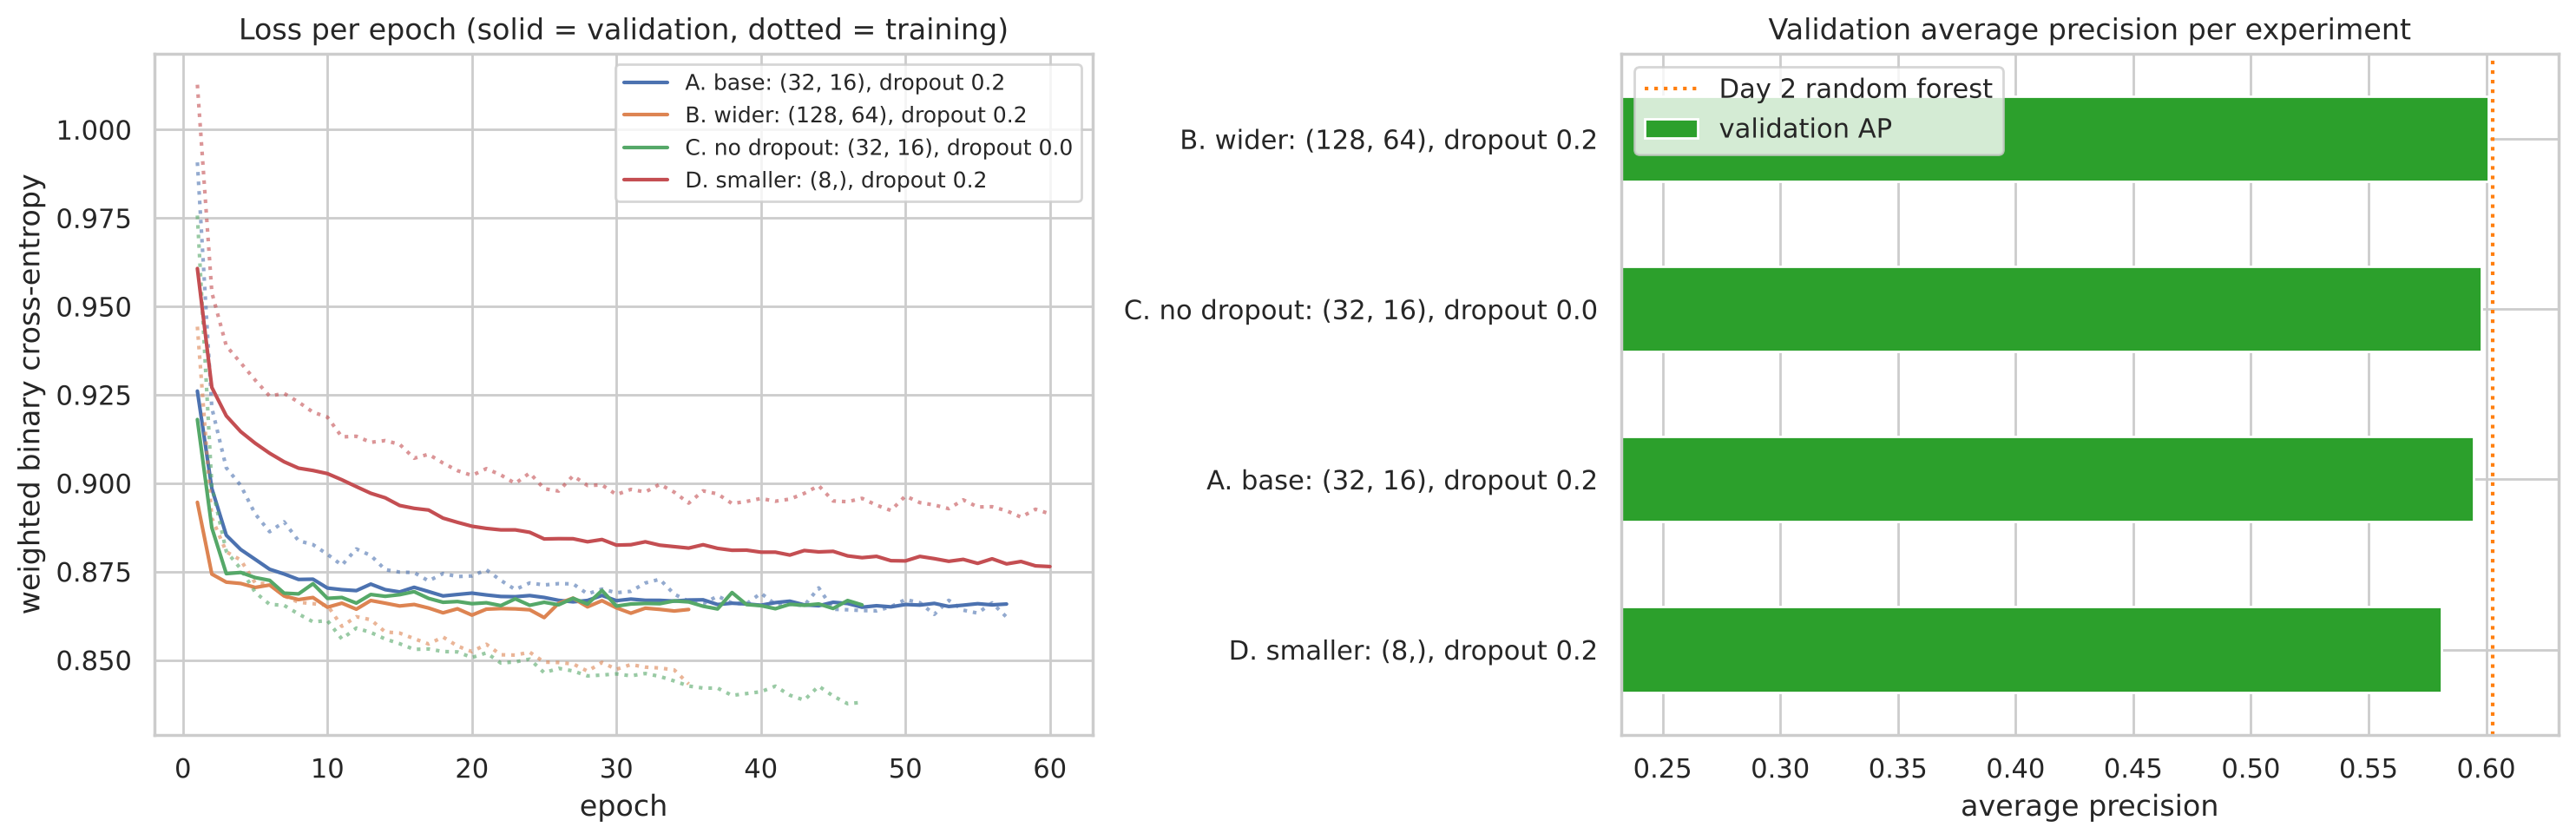

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, (model, hist, best, _) in runs.items():
    line, = axes[0].plot(hist.index, hist["validation loss"], label=name)
    axes[0].plot(hist.index, hist["train loss"], color=line.get_color(), ls=":", alpha=0.6)
axes[0].set(title="Loss per epoch (solid = validation, dotted = training)", xlabel="epoch", ylabel="weighted binary cross-entropy")
axes[0].legend(fontsize=9)
tuning_table["validation AP"].sort_values().plot.barh(ax=axes[1], color="tab:green")
axes[1].axvline(average_precision_score(y_val, rf_val_proba), color="tab:orange", ls=":", label="Day 2 random forest")
axes[1].set(title="Validation average precision per experiment", xlabel="average precision", ylabel="")
axes[1].set_xlim(y_val.mean(), None)
axes[1].legend()
plt.tight_layout()
save_fig("05_tuning_experiments")
plt.show()

In [19]:
best_name = tuning_table["validation AP"].idxmax()
final_mlp, final_history, final_epoch, final_settings = runs[best_name]
final_val_proba = predict_proba(final_mlp, X_val_t)
f2s = [fbeta_score(y_val, (final_val_proba >= t).astype(int), beta=2) for t in thresholds]
MLP_THRESHOLD = float(thresholds[int(np.argmax(f2s))])
print(f"Final network: {best_name}  (settings {final_settings}), threshold {MLP_THRESHOLD:.2f}")

Final network: B. wider: (128, 64), dropout 0.2  (settings {'hidden': (128, 64), 'dropout': 0.2}), threshold 0.30


> ✏️ **Team reading (write in your own words):** did any change make a real difference, or are the differences within noise? What does that say about this problem?

## 6. Test set (used once)

The final network and the Day 2 random forest (trained on train + validation, threshold 0.30) on the **Day 2 test set**.

In [20]:
day2_model.fit(X_trainval, y_trainval)
rf_test_proba = day2_model.predict_proba(X_test)[:, 1]
mlp_test_proba = predict_proba(final_mlp, X_test_t)

test_table = pd.DataFrame({
    "Always UNSAFE ('inspect everything')": scores(y_test, np.ones(len(y_test)), 0.5),
    "Random": scores(y_test, rng.random(len(y_test)), 1 - y_train.mean()),
    "Day 2 random forest (thr. 0.30)": scores(y_test, rf_test_proba, RF_THRESHOLD),
    f"MLP (thr. {MLP_THRESHOLD:.2f})": scores(y_test, mlp_test_proba, MLP_THRESHOLD),
}).T
test_table

,F2,recall,precision,balanced accuracy,average precision
Always UNSAFE ('inspect everything'),0.602,1.000,0.232,0.500,0.232
Random,0.231,0.231,0.230,0.499,0.233
Day 2 random forest (thr. 0.30),0.631,0.915,0.281,0.604,0.605
MLP (thr. 0.30),0.629,0.910,0.281,0.604,0.601


Figure saved to ../figures/06_test_confusion_matrices.png


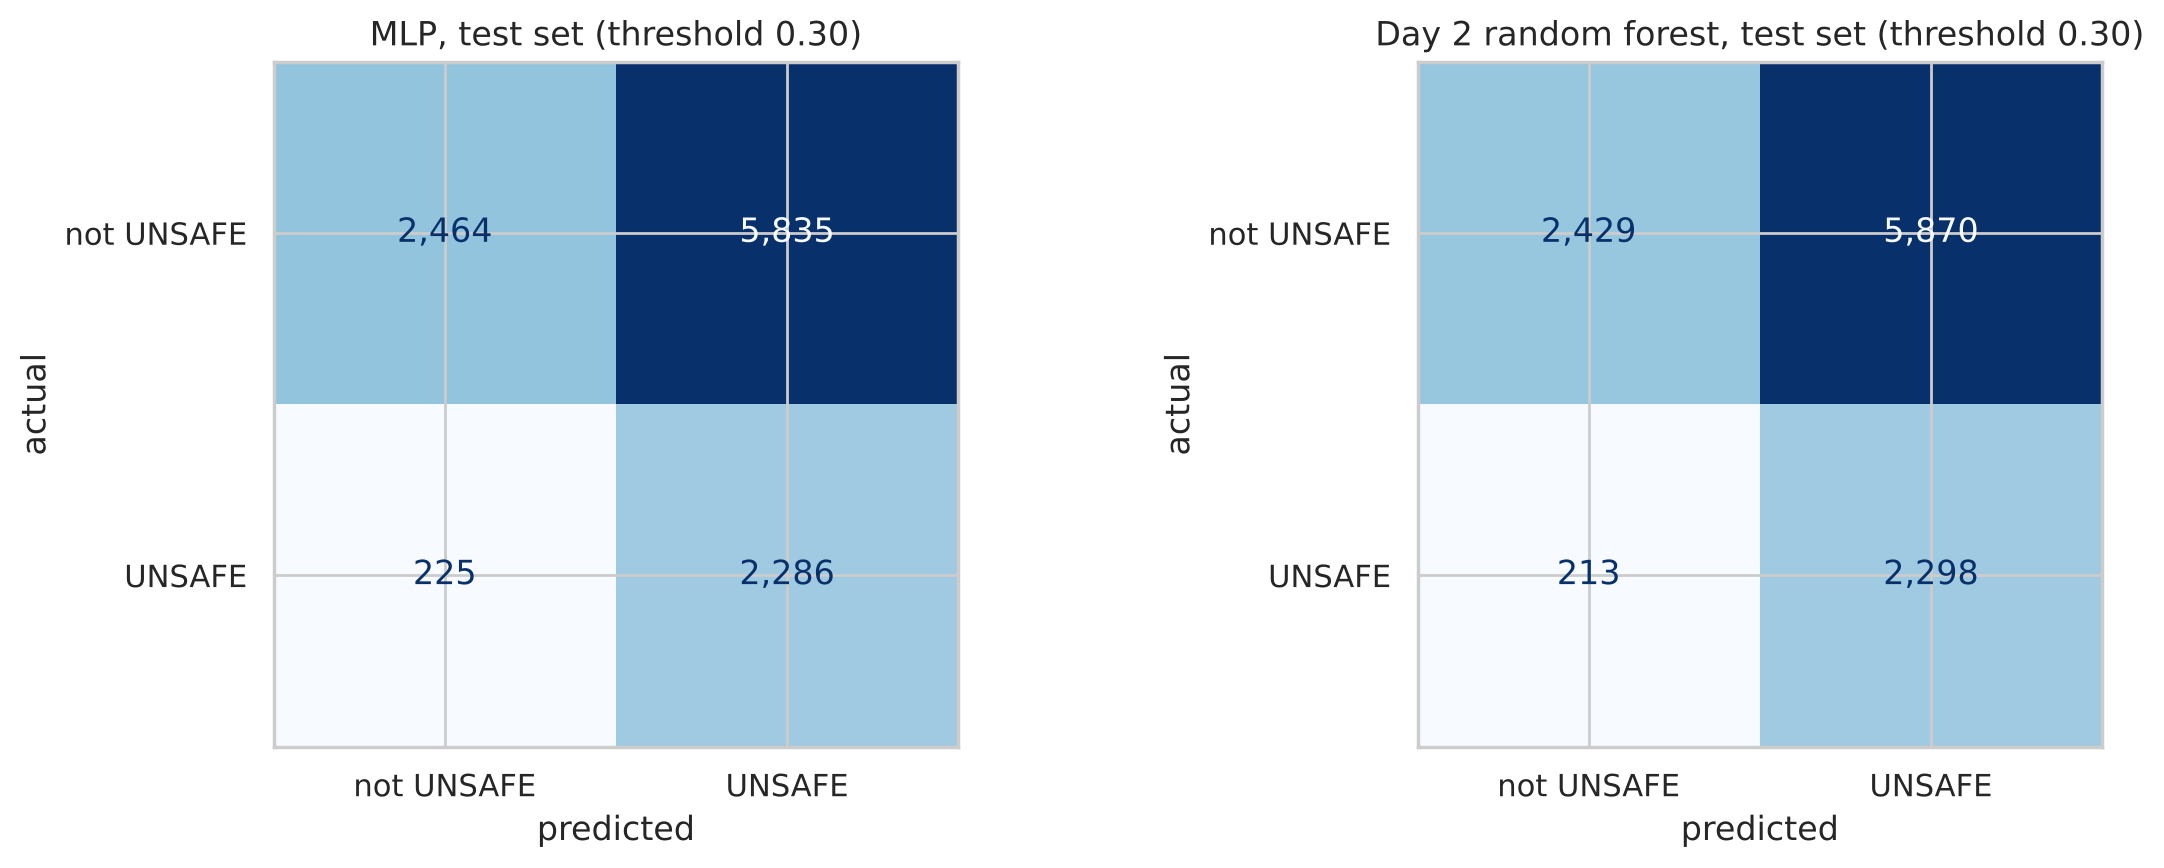

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, proba, thr) in zip(axes, [("MLP", mlp_test_proba, MLP_THRESHOLD),
                                         ("Day 2 random forest", rf_test_proba, RF_THRESHOLD)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (proba >= thr).astype(int)),
                           display_labels=["not UNSAFE", "UNSAFE"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set_title(f"{name}, test set (threshold {thr:.2f})")
    ax.set(xlabel="predicted", ylabel="actual")
plt.tight_layout()
save_fig("06_test_confusion_matrices")
plt.show()

Figure saved to ../figures/07_test_comparison.png


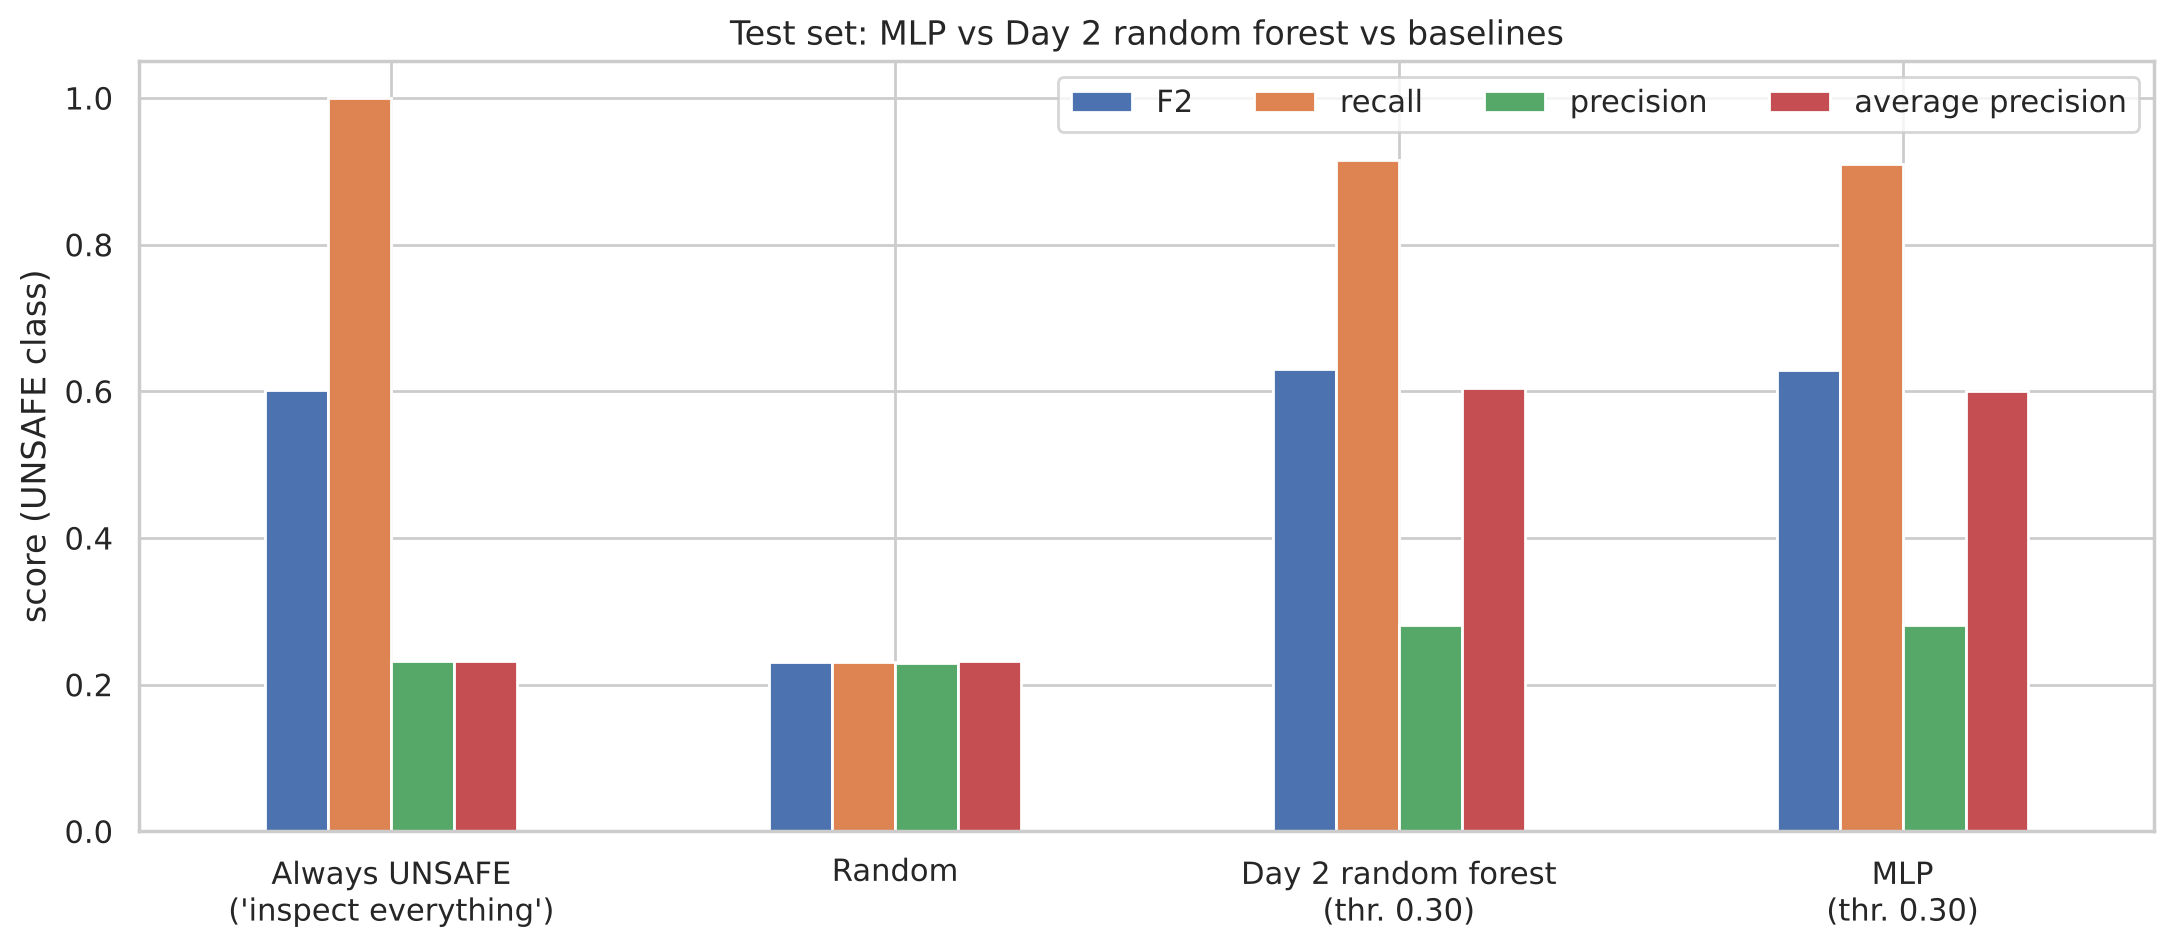

In [22]:
ax = test_table[["F2", "recall", "precision", "average precision"]].plot.bar(figsize=(13, 5), rot=0)
ax.set(title="Test set: MLP vs Day 2 random forest vs baselines", ylabel="score (UNSAFE class)", ylim=(0, 1.05))
ax.set_xticklabels([t.get_text().replace(" (", "\n(") for t in ax.get_xticklabels()])
ax.legend(loc="upper right", ncols=4)
save_fig("07_test_comparison")
plt.show()

Figure saved to ../figures/08_inspection_ranking.png


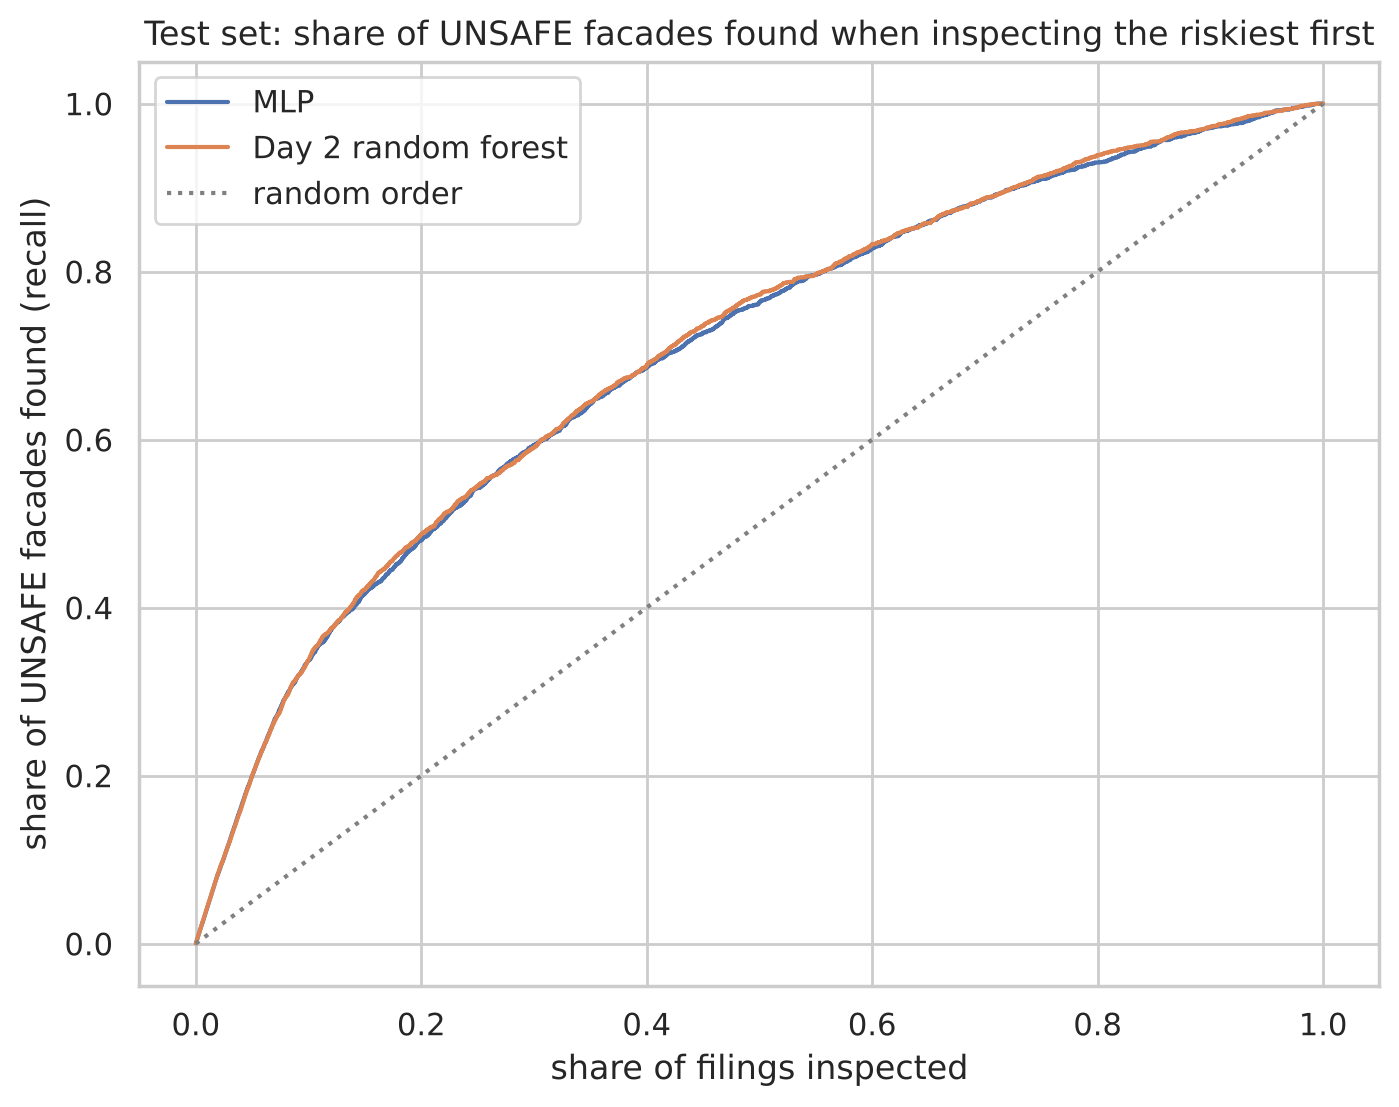

,MLP,Day 2 random forest
inspect first,,
top 10%,0.337,0.338
top 20%,0.481,0.489
top 30%,0.601,0.601


In [23]:
def found_curve(y_true, proba):
    order = np.argsort(-proba)
    found = np.cumsum(y_true.to_numpy()[order]) / y_true.sum()
    share = np.arange(1, len(order) + 1) / len(order)
    return share, found


fig, ax = plt.subplots(figsize=(8, 6))
for name, proba in [("MLP", mlp_test_proba), ("Day 2 random forest", rf_test_proba)]:
    ax.plot(*found_curve(y_test, proba), label=name)
ax.plot([0, 1], [0, 1], color="grey", ls=":", label="random order")
ax.set(title="Test set: share of UNSAFE facades found when inspecting the riskiest first",
       xlabel="share of filings inspected", ylabel="share of UNSAFE facades found (recall)")
ax.legend()
save_fig("08_inspection_ranking")
plt.show()

rows = []
for share in [0.10, 0.20, 0.30]:
    rows.append({"inspect first": f"top {share:.0%}",
                 **{name: y_test[proba >= np.quantile(proba, 1 - share)].sum() / y_test.sum()
                    for name, proba in [("MLP", mlp_test_proba), ("Day 2 random forest", rf_test_proba)]}})
pd.DataFrame(rows).set_index("inspect first").round(3)

> ✏️ **Team reading (write in your own words):** does the network beat the Day 2 model, tie, or lose? Is the difference bigger than the noise you saw in section 5? Why might a neural network not help much on 19 yes/no and category features?

## 7. Application: hand-made buildings

Four buildings we describe ourselves (not in the dataset), as a facade consultant might before a new cycle.

Figure saved to ../figures/09_design_options.png


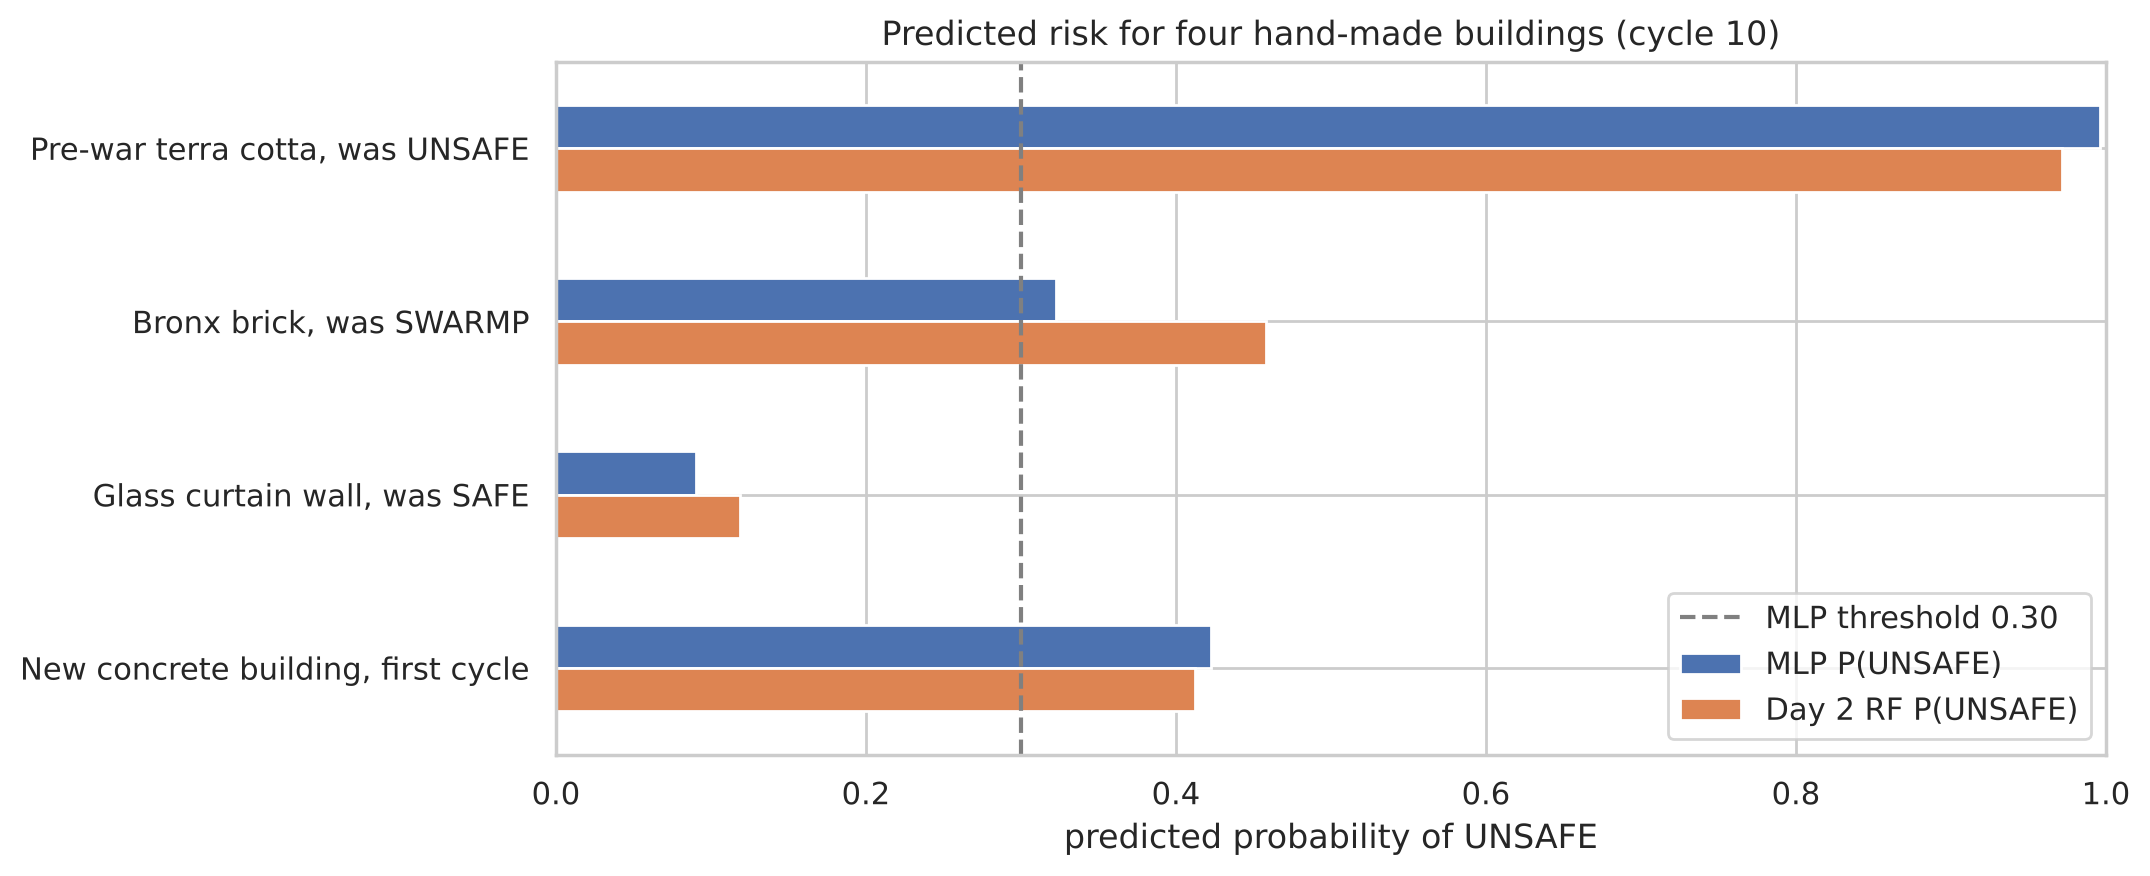

,MLP P(UNSAFE),Day 2 RF P(UNSAFE),MLP decision
"Pre-war terra cotta, was UNSAFE",0.996,0.971,inspect first
"Bronx brick, was SWARMP",0.323,0.458,inspect first
"Glass curtain wall, was SAFE",0.090,0.119,later
"New concrete building, first cycle",0.423,0.413,inspect first


In [24]:
def building(prior, borough, cycle, materials=(), walls=()):
    row = {"PRIOR_STATUS": prior, "BOROUGH": borough, "CYCLE": str(cycle)}
    row.update({c: float(c in [f"MATERIAL_{m}" for m in materials]) for c in material_features})
    row.update({c: float(c in [f"WALL_TYPE_{w}" for w in walls]) for c in wall_features})
    return row


options = pd.DataFrame([
    building("UNSAFE", "MANHATTAN", 10, ["TERRA_COTTA", "MASONRY"], ["TERRA_COTTA", "STEEL_FRAME"]),
    building("SWARMP", "BRONX", 10, ["MASONRY"], ["BRICK_MASONRY"]),
    building("SAFE", "MANHATTAN", 10, ["GLASS", "METAL"], ["STEEL_FRAME"]),
    building("NO PRIOR CYCLE", "BROOKLYN", 10, ["CONCRETE"], ["CONCRETE_FRAME"]),
], index=["Pre-war terra cotta, was UNSAFE", "Bronx brick, was SWARMP", "Glass curtain wall, was SAFE",
          "New concrete building, first cycle"])[features]

options_t = torch.tensor(preprocess.transform(options), dtype=torch.float32)
application = pd.DataFrame({"MLP P(UNSAFE)": predict_proba(final_mlp, options_t),
                            "Day 2 RF P(UNSAFE)": day2_model.predict_proba(options)[:, 1]}, index=options.index)
application["MLP decision"] = np.where(application["MLP P(UNSAFE)"] >= MLP_THRESHOLD, "inspect first", "later")

ax = application[["MLP P(UNSAFE)", "Day 2 RF P(UNSAFE)"]].plot.barh(figsize=(10, 4.5))
ax.axvline(MLP_THRESHOLD, color="grey", ls="--", label=f"MLP threshold {MLP_THRESHOLD:.2f}")
ax.set(title="Predicted risk for four hand-made buildings (cycle 10)", xlabel="predicted probability of UNSAFE", xlim=(0, 1))
ax.invert_yaxis()
ax.legend()
save_fig("09_design_options")
plt.show()
application.round(3)

> ✏️ **Team reading (write in your own words):** are the rankings plausible to someone who knows facades? Where do the two models disagree?

## 8. Save, reload, use

- `models/model.pt`: the network's weights (`state_dict`)
- `models/scaler.joblib`: the fitted preprocessing (imputation + one-hot + `StandardScaler`), needed to turn a table row into network inputs
- `models/config.json`: architecture settings, feature and class order, threshold

In [25]:
torch.save(final_mlp.state_dict(), MODEL_DIR / "model.pt")
joblib.dump(preprocess, MODEL_DIR / "scaler.joblib")
config = {"hidden": list(final_settings["hidden"]), "dropout": final_settings["dropout"], "n_inputs": N_INPUTS,
          "features": features, "nominal_features": nominal_features, "binary_features": binary_features,
          "network_inputs": input_names, "classes": {"0": "not UNSAFE (SAFE or SWARMP)", "1": "UNSAFE"},
          "output": "one logit; sigmoid(logit) = P(UNSAFE)", "threshold": MLP_THRESHOLD}
(MODEL_DIR / "config.json").write_text(json.dumps(config, indent=2))

# Reload into new objects, as a user would
cfg = json.loads((MODEL_DIR / "config.json").read_text())
reloaded = make_mlp(n_inputs=cfg["n_inputs"], hidden=tuple(cfg["hidden"]), dropout=cfg["dropout"])
reloaded.load_state_dict(torch.load(MODEL_DIR / "model.pt", map_location="cpu"))
reloaded.eval()
reloaded_preprocess = joblib.load(MODEL_DIR / "scaler.joblib")

example = options.iloc[[0]]
with torch.no_grad():
    p = torch.sigmoid(reloaded(torch.tensor(reloaded_preprocess.transform(example[cfg["features"]]), dtype=torch.float32))).item()
print(f"{example.index[0]}: P(UNSAFE) = {p:.3f} -> {'inspect first' if p >= cfg['threshold'] else 'later'}")
print("Same as before saving:", np.isclose(p, application.iloc[0, 0]))

Pre-war terra cotta, was UNSAFE: P(UNSAFE) = 0.996 -> inspect first
Same as before saving: True


In [26]:
# Model-card figures: copied into models/ (uploaded to Hugging Face with the card)
import shutil

for name in ["01_training_curves", "06_test_confusion_matrices", "07_test_comparison", "08_inspection_ranking"]:
    shutil.copy(FIG_DIR / f"{name}.png", MODEL_DIR / f"{name}.png")
print(sorted(p.name for p in MODEL_DIR.iterdir()))

['01_training_curves.png', '06_test_confusion_matrices.png', '07_test_comparison.png', '08_inspection_ranking.png', 'config.json', 'model.pt', 'scaler.joblib']


## 9. Conclusions

The numbers below are printed from this run, to copy into the findings, the README and the model card.

In [27]:
print(f"Final network: {best_name}, {sum(p.numel() for p in final_mlp.parameters()):,} parameters, "
      f"best epoch {final_epoch}, threshold {MLP_THRESHOLD:.2f}")
print(test_table.round(3).to_string())

Final network: B. wider: (128, 64), dropout 0.2, 12,417 parameters, best epoch 25, threshold 0.30
                                        F2  recall  precision  balanced accuracy  average precision
Always UNSAFE ('inspect everything') 0.602   1.000      0.232              0.500              0.232
Random                               0.231   0.231      0.230              0.499              0.233
Day 2 random forest (thr. 0.30)      0.631   0.915      0.281              0.604              0.605
MLP (thr. 0.30)                      0.629   0.910      0.281              0.604              0.601


> ✏️ **Team conclusions (3–6 findings with numbers, in your own words).** For example:
>
> 1. On the Day 2 test set the MLP reaches F2 … and average precision … against … for the Day 2 random forest.
> 2. Training: … (stopping epoch, overfitting or not).
> 3. What the network relies on: … (section 4).
> 4. Tuning: … (did width/dropout matter?).
> 5. Ranking: inspecting the riskiest 10% / 20% finds …% / …% of UNSAFE facades.
>
> **Limitations and biases:** the same as Day 2 (the model mostly repeats the previous inspection result; no building age, height or
> exposure; the label is a human judgement; NYC only, buildings over 6 stories) plus …
>
> **The model should not be used for:** replacing an inspection, judging a single building's safety, other cities, …